In [7]:
import numpy as np
import pandas as pd
import seaborn as sns

In [8]:
df=pd.read_csv("Wholesale customers data.csv")
df.head(5)

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [9]:
df=df.dropna()

In [10]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df=scaler.fit_transform(df)

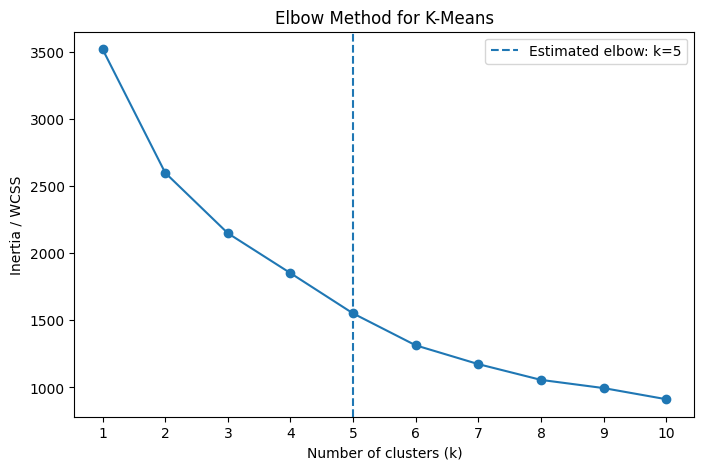

Automatic elbow estimate: k = 5


In [11]:
from sklearn.cluster import KMeans, DBSCAN
import matplotlib.pyplot as plt
k_values = list(range(1, 11))
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(df)
    inertias.append(model.inertia_)

# Simple geometric elbow estimate: maximum distance to line from first to last point.
points = np.column_stack([k_values, inertias]).astype(float)
first, last = points[0], points[-1]
line_vec = last - first
line_unit = line_vec / np.linalg.norm(line_vec)
vec_from_first = points - first
projection = np.outer(vec_from_first @ line_unit, line_unit)
perpendicular = vec_from_first - projection
distances = np.linalg.norm(perpendicular, axis=1)

# Ignore k=1 and the last k as possible elbow candidates.
distances[0] = -np.inf
distances[-1] = -np.inf
elbow_k = int(points[np.argmax(distances), 0])

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.axvline(elbow_k, linestyle="--", label=f"Estimated elbow: k={elbow_k}")
plt.xticks(k_values)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia / WCSS")
plt.title("Elbow Method for K-Means")
plt.legend()
plt.show()

print(f"Automatic elbow estimate: k = {elbow_k}")

In [12]:
kmeans = KMeans(n_clusters=elbow_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(df)

print("K-Means cluster counts:")
display(pd.Series(kmeans_labels, name="cluster").value_counts().sort_index().to_frame("count"))

K-Means cluster counts:


,count
cluster,
0,6
1,126
2,91
3,207
4,10


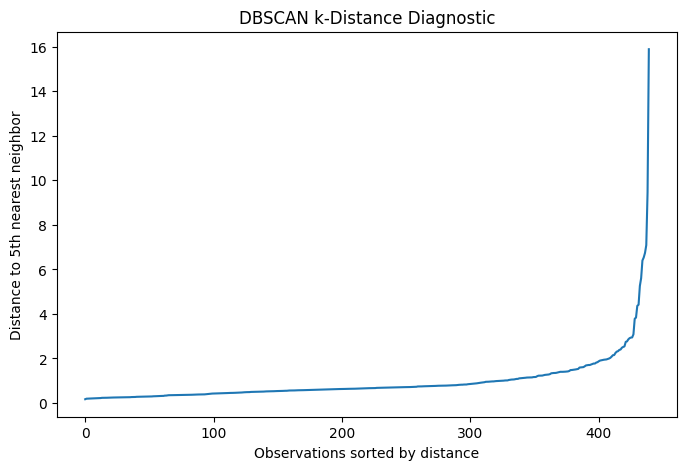

Useful reference percentiles:
70th percentile: 0.903
75th percentile: 1.018
80th percentile: 1.174
85th percentile: 1.405
90th percentile: 1.749
95th percentile: 2.405


In [13]:
##DBSCAN
from sklearn.neighbors import NearestNeighbors
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(df)
distances_nn, _ = neighbors.kneighbors(df)

# Distance to each point's kth nearest neighbor.
k_distances = np.sort(distances_nn[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel("Observations sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.title("DBSCAN k-Distance Diagnostic")
plt.show()

print("Useful reference percentiles:")
for p in [70, 75, 80, 85, 90, 95]:
    print(f"{p}th percentile: {np.percentile(k_distances, p):.3f}")

In [14]:
eps = 2.4

dbscan = DBSCAN(eps=eps, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(df)

n_dbscan_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int(np.sum(dbscan_labels == -1))

print(f"DBSCAN clusters (excluding noise): {n_dbscan_clusters}")
print(f"Noise points: {n_noise} of {len(dbscan_labels)} ({n_noise/len(dbscan_labels):.1%})")
print()
print("DBSCAN label counts (-1 means noise):")
display(pd.Series(dbscan_labels, name="cluster").value_counts().sort_index().to_frame("count"))

DBSCAN clusters (excluding noise): 1
Noise points: 14 of 440 (3.2%)

DBSCAN label counts (-1 means noise):


,count
cluster,
-1,14
0,426


In [15]:
comparison = pd.DataFrame({
    "KMeans": kmeans_labels,
    "DBSCAN": dbscan_labels
})

print("Cross-tabulation of assigned labels:")
display(pd.crosstab(comparison["KMeans"], comparison["DBSCAN"], margins=True))

Cross-tabulation of assigned labels:


DBSCAN,-1,0,All
KMeans,,,
0,6,0,6
1,0,126,126
2,0,91,91
3,1,206,207
4,7,3,10
All,14,426,440


In [18]:
from sklearn.metrics import silhouette_score, adjusted_rand_score
kmeans_sil = silhouette_score(df, kmeans_labels)

non_noise = dbscan_labels != -1
dbscan_non_noise_labels = dbscan_labels[non_noise]
unique_dbscan_non_noise = np.unique(dbscan_non_noise_labels)

if len(unique_dbscan_non_noise) >= 2:
    dbscan_sil = silhouette_score(X_scaled[non_noise], dbscan_non_noise_labels)
else:
    dbscan_sil = np.nan

ari_between_algorithms = adjusted_rand_score(kmeans_labels, dbscan_labels)

metrics = pd.DataFrame({
    "Metric": [
        "Number of clusters",
        "Noise points",
        "Silhouette score",
        "ARI between K-Means and DBSCAN"
    ],
    "K-Means": [elbow_k, 0, kmeans_sil, ari_between_algorithms],
    "DBSCAN": [n_dbscan_clusters, n_noise, dbscan_sil, ari_between_algorithms]
})

display(metrics.round(3))

,Metric,K-Means,DBSCAN
0,Number of clusters,5.000,1.00
1,Noise points,0.000,14.00
2,Silhouette score,0.353,NaN
3,ARI between K-Means and DBSCAN,0.060,0.06


In [20]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df)

explained = pca.explained_variance_ratio_
print(f"PC1 explained variance: {explained[0]:.1%}")
print(f"PC2 explained variance: {explained[1]:.1%}")
print(f"Total shown in 2D:       {explained.sum():.1%}")

PC1 explained variance: 38.8%
PC2 explained variance: 22.4%
Total shown in 2D:       61.1%


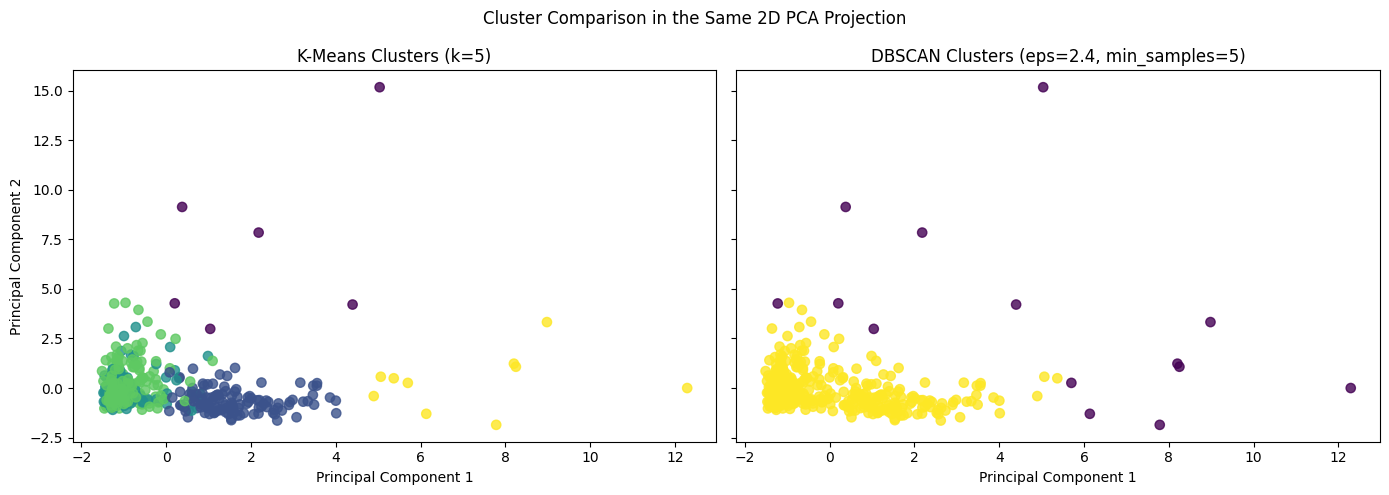

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="viridis", s=45, alpha=0.8)
axes[0].set_title(f"K-Means Clusters (k={elbow_k})")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

scatter = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap="viridis", s=45, alpha=0.8)
axes[1].set_title(f"DBSCAN Clusters (eps={eps}, min_samples={min_samples})")
axes[1].set_xlabel("Principal Component 1")

plt.suptitle("Cluster Comparison in the Same 2D PCA Projection")
plt.tight_layout()
plt.show() # as we captured the max variance in these 2 pc's we can see vizulization in both k means and dbscan